In [1]:
import pandas as pd

path = r"C:\Users\szymo\OneDrive\Pulpit\python\magisterka_cost_anomalies\data_raw\SCMS_Delivery_History_Dataset_20150929.csv"

df = pd.read_csv(path, encoding="latin1")

df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


### ŁADOWANIE DANYCH I SPRAWDZENIE POPRAWNOŚCI ŁADOWANIA

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

# SPRAWDZENIE WARTOSCI W KOLUMNACH, ICH TYPOW, NAZW, ILOSCI ZDUPLIKOWANYCH WIERSZY, BRAKUJACYCH DANYCH

In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10324.0,NaN,NaN,NaN,51098.968229,31944.332496,1.0,12795.75,57540.5,83648.25,86823.0
Project Code,10324,142,116-ZA-T30,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PQ #,10324,1237,Pre-PQ Process,2681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PO / SO #,10324,6233,SCMS-199289,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ASN/DN #,10324,7030,ASN-19166,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,10324,43,South Africa,1406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Managed By,10324,4,PMO - US,10265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfill Via,10324,2,From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vendor INCO Term,10324,8,N/A - From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shipment Mode,9964,4,Air,6113,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for i, col in enumerate(df.columns):
    print(i, col)

0 ID
1 Project Code
2 PQ #
3 PO / SO #
4 ASN/DN #
5 Country
6 Managed By
7 Fulfill Via
8 Vendor INCO Term
9 Shipment Mode
10 PQ First Sent to Client Date
11 PO Sent to Vendor Date
12 Scheduled Delivery Date
13 Delivered to Client Date
14 Delivery Recorded Date
15 Product Group
16 Sub Classification
17 Vendor
18 Item Description
19 Molecule/Test Type
20 Brand
21 Dosage
22 Dosage Form
23 Unit of Measure (Per Pack)
24 Line Item Quantity
25 Line Item Value
26 Pack Price
27 Unit Price
28 Manufacturing Site
29 First Line Designation
30 Weight (Kilograms)
31 Freight Cost (USD)
32 Line Item Insurance (USD)


In [5]:
print("Liczba wierszy i kolumn:", df.shape)
df.dtypes

Liczba wierszy i kolumn: (10324, 33)


ID                                int64
Project Code                     object
PQ #                             object
PO / SO #                        object
ASN/DN #                         object
Country                          object
Managed By                       object
Fulfill Via                      object
Vendor INCO Term                 object
Shipment Mode                    object
PQ First Sent to Client Date     object
PO Sent to Vendor Date           object
Scheduled Delivery Date          object
Delivered to Client Date         object
Delivery Recorded Date           object
Product Group                    object
Sub Classification               object
Vendor                           object
Item Description                 object
Molecule/Test Type               object
Brand                            object
Dosage                           object
Dosage Form                      object
Unit of Measure (Per Pack)        int64
Line Item Quantity                int64


In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().sum() / len(df) * 100).round(2)
})

missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78
Molecule/Test Type,0,0.00
Brand,0,0.00
Dosage Form,0,0.00
Unit of Measure (Per Pack),0,0.00
Line Item Quantity,0,0.00
Line Item Value,0,0.00
Vendor,0,0.00


In [7]:
df.duplicated().sum()

0

# UNIKALNE WARTOŚCI W KOLUMNACH TYPU OBJECT I LICZBOWYCH (FLOAT, INT)

In [8]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print("\n---", col, "---")
    print("Unique:", df[col].nunique())
    print(df[col].dropna().unique()[:10])


--- Project Code ---
Unique: 142
['100-CI-T01' '108-VN-T01' '112-NG-T01' '110-ZM-T01' '109-TZ-T01'
 '102-NG-T01' '107-RW-T01' '106-HT-T01' '113-ZW-T01' '104-CI-T01']

--- PQ # ---
Unique: 1237
['Pre-PQ Process' 'FPQ-4587' 'FPQ-12051' 'FPQ-14827' 'FPQ-9066'
 'FPQ-11754' 'FPQ-15276' 'FPQ-11670' 'FPQ-9231' 'FPQ-8671']

--- PO / SO # ---
Unique: 6233
['SCMS-4' 'SCMS-13' 'SCMS-20' 'SCMS-78' 'SCMS-81' 'SCMS-87' 'SCMS-139'
 'SCMS-140' 'SCMS-156' 'SCMS-165']

--- ASN/DN # ---
Unique: 7030
['ASN-8' 'ASN-85' 'ASN-14' 'ASN-50' 'ASN-55' 'ASN-57' 'ASN-130' 'ASN-94'
 'ASN-93' 'ASN-199']

--- Country ---
Unique: 43
["Côte d'Ivoire" 'Vietnam' 'Nigeria' 'Zambia' 'Tanzania' 'Rwanda' 'Haiti'
 'Zimbabwe' 'Ethiopia' 'South Africa']

--- Managed By ---
Unique: 4
['PMO - US' 'South Africa Field Office' 'Haiti Field Office'
 'Ethiopia Field Office']

--- Fulfill Via ---
Unique: 2
['Direct Drop' 'From RDC']

--- Vendor INCO Term ---
Unique: 8
['EXW' 'FCA' 'DDU' 'CIP' 'DDP' 'CIF' 'N/A - From RDC' 'DAP']

--- S

In [9]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
ID,10324.0,51098.968229,31944.332496,1.0,12795.7500,57540.500,83648.2500,86823.00
Unit of Measure (Per Pack),10324.0,77.990895,76.579764,1.0,30.0000,60.000,90.0000,1000.00
Line Item Quantity,10324.0,18332.534870,40035.302961,1.0,408.0000,3000.000,17039.7500,619999.00
Line Item Value,10324.0,157650.567347,345292.066979,0.0,4314.5925,30471.465,166447.1400,5951990.40
Pack Price,10324.0,21.910241,45.609223,0.0,4.1200,9.300,23.5925,1345.64
Unit Price,10324.0,0.611701,3.275808,0.0,0.0800,0.160,0.4700,238.65
Line Item Insurance (USD),10037.0,240.117626,500.190568,0.0,6.5100,47.040,252.4000,7708.44


# PRZEJSCIE DO MERITUM - ZNALEZIENIE KOLUMN ODPOWIADAJACYCH ZA KOSZT ORAZ WAGĘ/ILOŚĆ TRANSPORTOWANYCH DÓBR

In [10]:
cost_cols = [col for col in df.columns if "cost" in col.lower() or "price" in col.lower() or "value" in col.lower()]
cost_cols

['Line Item Value', 'Pack Price', 'Unit Price', 'Freight Cost (USD)']

In [11]:
qty_cols = [col for col in df.columns if "quantity" in col.lower() or "weight" in col.lower() or "unit" in col.lower()]
qty_cols

['Unit of Measure (Per Pack)',
 'Line Item Quantity',
 'Unit Price',
 'Weight (Kilograms)']

In [12]:
important_cols = [
    "Freight Cost (USD)",
    "Weight (Kilograms)",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Line Item Insurance (USD)",
    "Shipment Mode"
]

df[important_cols].dtypes

Freight Cost (USD)            object
Weight (Kilograms)            object
Line Item Quantity             int64
Line Item Value              float64
Pack Price                   float64
Unit Price                   float64
Line Item Insurance (USD)    float64
Shipment Mode                 object
dtype: object

In [13]:
df[["Freight Cost (USD)", "Weight (Kilograms)", "Shipment Mode"]].head(20)

,Freight Cost (USD),Weight (Kilograms),Shipment Mode
0,780.34,13,Air
1,4521.5,358,Air
2,1653.78,171,Air
3,16007.06,1855,Air
4,45450.08,7590,Air
5,5920.42,504,Air
6,Freight Included in Commodity Cost,328,Air
7,6212.41,1478,Air
8,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),Air
9,Freight Included in Commodity Cost,643,Air


In [14]:
df["Freight Cost (USD)"].astype(str).unique()[:50]

array(['780.34', '4521.5', '1653.78', '16007.06', '45450.08', '5920.42',
       'Freight Included in Commodity Cost', '6212.41',
       'See ASN-93 (ID#:1281)', '13569.49', 'Invoiced Separately',
       '64179.42', '1760.32', '3120.7', '912.96', '2682.47', '15893.71',
       '4193.49', '1767.38', '3518.38', '3097.85', '27869.74', '28461.1',
       '28359.8', '12237.61', '20885.78', '2282.57', '2149.05', '0.75',
       '5446.51', '2656.12', '360', '4112.46', '5468.88', '1715.17',
       '4051.34', '2211.05', '16090.22', '13507.92', '645.1', '782.13',
       '871.57', '18614.72', '1755.87', '10179.16', '4686.88', '180',
       '11062.05', '11298.13', '12830.91'], dtype=object)

In [15]:
df["Weight (Kilograms)"].astype(str).unique()[:50]

array(['13', '358', '171', '1855', '7590', '504', '328', '1478',
       'See ASN-93 (ID#:1281)', '643', '853',
       'Weight Captured Separately', '7416', '256', '710', '162', '341',
       '2278', '2126', '941', '117', '60', '3335', '4228', '3263', '76',
       '23', '99', '509', '206', '14', '373', '483', '33', '654', '81',
       '1251', '1537', '109', '54', '2719', '115', '2600', '1224', '34',
       '1053', '562', '1708', '46', '1'], dtype=object)

KONWERSJA KOLUMN OBJECT NA LICZBOWE (TYCH KTORE TEGO POTRZEBUJA)

In [16]:
def to_numeric_clean(series):
    return pd.to_numeric(
        series.astype(str)
              .str.replace(",", "", regex=False)
              .str.strip(),
        errors="coerce"
    )

df["freight_cost_usd_num"] = to_numeric_clean(
    df["Freight Cost (USD)"]
)

df["weight_kg_num"] = to_numeric_clean(
    df["Weight (Kilograms)"]
)

In [17]:
conversion_check = pd.DataFrame({
    "original_missing": [
        df["Freight Cost (USD)"].isna().sum(),
        df["Weight (Kilograms)"].isna().sum()
    ],
    "after_conversion_missing": [
        df["freight_cost_usd_num"].isna().sum(),
        df["weight_kg_num"].isna().sum()
    ]
}, index=["Freight Cost (USD)", "Weight (Kilograms)"])

conversion_check

,original_missing,after_conversion_missing
Freight Cost (USD),0,4126
Weight (Kilograms),0,3952


SPRAWDZENIE PROBLEMATYCZNYCH WARTOSCI KOSZTU I WAGI

In [18]:
df.loc[
    df["freight_cost_usd_num"].isna(),
    "Freight Cost (USD)"
].value_counts()

Freight Included in Commodity Cost    1442
Invoiced Separately                    239
See DN-304 (ID#:10589)                  16
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
                                      ... 
See DN-921 (ID#:11917)                   1
See DN-2914 (ID#:83089)                  1
See DN-1083 (ID#:12219)                  1
See DN-964 (ID#:10987)                   1
See DN-4282 (ID#:83919)                  1
Name: Freight Cost (USD), Length: 1301, dtype: int64

In [19]:
df.loc[
    df["weight_kg_num"].isna(),
    "Weight (Kilograms)"
].value_counts()

Weight Captured Separately    1507
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
                              ... 
See DN-1387 (ID#:11674)          1
See DN-2358 (ID#:82405)          1
See DN-2360 (ID#:82407)          1
See DN-1382 (ID#:10788)          1
See DN-4282 (ID#:83919)          1
Name: Weight (Kilograms), Length: 1300, dtype: int64

agregacja DN

In [66]:
reference_mask = (
    df["freight_cost_usd_num"].notna()
    & df["weight_kg_num"].notna()
)

reference_rows = df.loc[reference_mask].copy()

print("Rekordy z numerycznym kosztem i wagą:", len(reference_rows))
print(
    "Unikalne ASN/DN:",
    reference_rows["ASN/DN #"].nunique()
)


df["Line Item Quantity"] = pd.to_numeric(
    df["Line Item Quantity"],
    errors="coerce"
)

df["Line Item Value"] = pd.to_numeric(
    df["Line Item Value"],
    errors="coerce"
)


shipment_aggregates = (
    df.groupby("ASN/DN #", as_index=False)
      .agg(
          shipment_line_count=("ID", "size"),
          shipment_total_quantity=("Line Item Quantity", "sum"),
          shipment_total_value=("Line Item Value", "sum")
      )
)


df_cost = reference_rows.merge(
    shipment_aggregates,
    on="ASN/DN #",
    how="left"
)


df_cost["Shipment Mode"] = (
    df_cost["Shipment Mode"]
    .fillna("Unknown")
)


df_cost = df_cost[
    (df_cost["shipment_total_value"] > 0)
    & (df_cost["shipment_total_quantity"] > 0)
    & (df_cost["weight_kg_num"] > 0)
].copy()



df_cost["cost_per_kg"] = (
    df_cost["freight_cost_usd_num"]
    / df_cost["weight_kg_num"]
)

df_cost["cost_per_unit"] = (
    df_cost["freight_cost_usd_num"]
    / df_cost["shipment_total_quantity"]
)

df_cost["freight_to_value_ratio"] = (
    df_cost["freight_cost_usd_num"]
    / df_cost["shipment_total_value"]
)


print("Finalna liczba wysyłek:", len(df_cost))
print("Unikalne ASN/DN:", df_cost["ASN/DN #"].nunique())

Rekordy z numerycznym kosztem i wagą: 6175
Unikalne ASN/DN: 6175
Finalna liczba wysyłek: 6162
Unikalne ASN/DN: 6162


SPRAWDZENIE OCZYSZCZONEGO DATASETU

In [67]:
df_cost[[
    "Freight Cost (USD)",
    "freight_cost_usd_num",
    "Weight (Kilograms)",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "Shipment Mode"
]].isna().sum()

Freight Cost (USD)         0
freight_cost_usd_num       0
Weight (Kilograms)         0
weight_kg_num              0
shipment_total_quantity    0
shipment_total_value       0
Shipment Mode              0
dtype: int64

In [68]:
df_cost["Shipment Mode"] = df_cost["Shipment Mode"].fillna("Unknown")

In [23]:
df_cost["Shipment Mode"].isna().sum()

0

In [69]:
df_cost["Shipment Mode"].value_counts()

Air            4085
Truck          1161
Air Charter     423
Ocean           282
Unknown         211
Name: Shipment Mode, dtype: int64

SPRAWDZANIE WARTOŚCI SKRANJNYCH (INF) I CZYSZCZENIE POD ML

In [70]:
check_cols = [
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]

df_cost[check_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
cost_per_kg,6162.0,38.973183,582.345900,0.000539,3.042546,7.234149,14.833771,31087.705
cost_per_unit,6162.0,22.066342,379.537639,0.000500,0.300230,0.858791,3.635739,14515.010
freight_to_value_ratio,6162.0,23.890256,1714.328819,0.000112,0.036016,0.087658,0.201505,134494.000


In [26]:
import numpy as np

for col in check_cols:
    print(col)
    print("NaN:", df_cost[col].isna().sum())
    print("inf:", np.isinf(df_cost[col]).sum())
    print()

cost_per_kg
NaN: 0
inf: 0

cost_per_unit
NaN: 0
inf: 0

freight_to_value_ratio
NaN: 0
inf: 0



In [27]:
import numpy as np

check_cols = [
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]

for col in check_cols:
    print(col)
    print("NaN:", df_cost[col].isna().sum())
    print("inf:", np.isinf(df_cost[col]).sum())
    print()

cost_per_kg
NaN: 0
inf: 0

cost_per_unit
NaN: 0
inf: 0

freight_to_value_ratio
NaN: 0
inf: 0



In [28]:
df_cost[[
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
cost_per_kg,6162.0,38.973183,582.345900,0.000539,3.042546,7.234149,14.833771,31087.705
cost_per_unit,6162.0,22.066342,379.537639,0.000500,0.300230,0.858791,3.635739,14515.010
freight_to_value_ratio,6162.0,23.890256,1714.328819,0.000112,0.036016,0.087658,0.201505,134494.000


In [71]:
df_cost.sort_values("cost_per_kg", ascending=False)[[
    "freight_cost_usd_num",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio",
    "Shipment Mode"
]].head(15)

,freight_cost_usd_num,weight_kg_num,shipment_total_quantity,shipment_total_value,cost_per_kg,cost_per_unit,freight_to_value_ratio,Shipment Mode
6005,124350.82,4.0,64,156.16,31087.705000,1942.981563,796.303919,Air Charter
5515,45180.62,2.0,10534,97966.20,22590.310000,4.289028,0.461186,Air Charter
852,19480.97,1.0,5,58.75,19480.970000,3896.194000,331.590979,Air
543,9789.07,1.0,2,160.00,9789.070000,4894.535000,61.181687,Unknown
148,12561.40,2.0,5,160.00,6280.700000,2512.280000,78.508750,Air
6102,5220.79,1.0,25,169.00,5220.790000,208.831600,30.892249,Truck
3294,4116.81,1.0,2,5.06,4116.810000,2058.405000,813.598814,Air
5429,3253.88,1.0,1004,8534.00,3253.880000,3.240916,0.381284,Air
3425,5110.28,2.0,655,65500.00,2555.140000,7.801954,0.078020,Air
2005,1979.10,1.0,311,9952.00,1979.100000,6.363666,0.198865,Air


In [30]:
import os

os.makedirs(
    r"C:\Users\szymo\OneDrive\Pulpit\python\magisterka_cost_anomalies\data_interim",
    exist_ok=True
)

In [31]:
df_cost.to_csv(
    r"C:\Users\szymo\OneDrive\Pulpit\python\magisterka_cost_anomalies\data_interim\shipments_cost_cleaned.csv",
    index=False
)

In [32]:
cleaning_summary = pd.DataFrame({
    "Etap": [
        "Wiersze w zbiorze źródłowym",
        "Unikalne ASN/DN w zbiorze źródłowym",
        "Wysyłki z numerycznym kosztem frachtu i masą",
        "Finalny zbiór analityczny"
    ],
    "Liczba obserwacji": [
        len(df),
        df["ASN/DN #"].nunique(),
        len(reference_rows),
        len(df_cost)
    ]
})

cleaning_summary

,Etap,Liczba obserwacji
0,Wiersze w zbiorze źródłowym,10324
1,Unikalne ASN/DN w zbiorze źródłowym,7030
2,Wysyłki z numerycznym kosztem frachtu i masą,6175
3,Finalny zbiór analityczny,6162


# Podstawowy opis finalnego zbioru i statystyki z podzialem na kategorie

In [72]:
df_cost[[
    "freight_cost_usd_num",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
freight_cost_usd_num,6162.0,11119.539257,15841.185511,0.750000,2143.492500,5886.900000,14416.642500,289653.200
weight_kg_num,6162.0,3435.948718,13677.316176,1.000000,210.000000,1054.000000,3336.000000,857354.000
shipment_total_quantity,6162.0,28747.949043,59266.405950,1.000000,1260.500000,6200.000000,30308.000000,834063.000
shipment_total_value,6162.0,245717.451594,495928.396640,0.010000,15038.830000,78794.000000,266144.535000,8140454.880
cost_per_kg,6162.0,38.973183,582.345900,0.000539,3.042546,7.234149,14.833771,31087.705
cost_per_unit,6162.0,22.066342,379.537639,0.000500,0.300230,0.858791,3.635739,14515.010
freight_to_value_ratio,6162.0,23.890256,1714.328819,0.000112,0.036016,0.087658,0.201505,134494.000


In [73]:
df_cost.groupby("Shipment Mode")[[
    "freight_cost_usd_num",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]].agg(["count", "mean", "median", "std", "min", "max"])

freight_cost_usd_num                                         \
                             count          mean     median           std   
Shipment Mode                                                               
Air                           4085  10476.525770   4784.190  16117.182490   
Air Charter                    423  21004.150662  15322.730  20117.354133   
Ocean                          282  12733.080816   9520.975  12454.296485   
Truck                         1161  10206.553144   6002.000  13151.653857   
Unknown                        211   6619.433223   2921.000  10042.754568   

                                 cost_per_kg                         \
                  min        max       count        mean     median   
Shipment Mode                                                         
Air              0.75  289653.20        4085   33.566004  10.013730   
Air Charter    134.00  194623.44         423  162.328929   4.317785   
Ocean          146.50  102761.99         282   20.662666   1.681020   
Truck           22.29  131278.81        1161   14.436741   2.501434   
Unknown        186.25   88801.00         211   55.841524   4.654915   

                            ... cost_per_unit                        \
                       std  ...        median         std       min   
Shipment Mode               ...                                       
Air             341.470719  ...      1.755461  458.430725  0.000500   
Air Charter    1867.328805  ...      0.438141   94.887270  0.049697   
Ocean           160.559982  ...      0.155494   13.932492  0.005319   
Truck           165.449078  ...      0.251034    6.816937  0.008099   
Unknown         673.549824  ...      0.567074  339.947061  0.042139   

                            freight_to_value_ratio                       \
                        max                  count       mean    median   
Shipment Mode                                                             
Air            14515.010000                   4085  34.867984  0.112026   
Air Charter     1942.981563                    423   2.435921  0.060176   
Ocean            162.658167                    282   0.383685  0.031379   
Truck            208.831600                   1161   3.060006  0.040487   
Unknown         4894.535000                    211   0.401812  0.046904   

                                                     
                       std       min            max  
Shipment Mode                                        
Air            2104.849672  0.000112  134494.000000  
Air Charter      38.739288  0.001893     796.303919  
Ocean             2.950392  0.001179      36.066112  
Truck            96.857914  0.001125    3300.000000  
Unknown           4.211424  0.001687      61.181687  

[5 rows x 24 columns]

# KROK MILOWY - USTALENIE WSKAŹNIKU NA PODSTAWIE MEDIANY - CZY DANY TRANSPORT JEST DROGI/TANI NA PODSTAWIE INNYCH PRZESYLEK Z TEGO SAMEGO RODZAJU TRANSPORTU!!!!

In [74]:
df_cost["median_freight_by_mode"] = (
    df_cost.groupby("Shipment Mode")["freight_cost_usd_num"].transform("median")
)

df_cost["median_cost_per_kg_by_mode"] = (
    df_cost.groupby("Shipment Mode")["cost_per_kg"].transform("median")
)

df_cost["median_cost_per_unit_by_mode"] = (
    df_cost.groupby("Shipment Mode")["cost_per_unit"].transform("median")
)

In [75]:
df_cost["freight_vs_mode_median"] = (
    df_cost["freight_cost_usd_num"] / df_cost["median_freight_by_mode"]
)

df_cost["cost_per_kg_vs_mode_median"] = (
    df_cost["cost_per_kg"] / df_cost["median_cost_per_kg_by_mode"]
)

df_cost["cost_per_unit_vs_mode_median"] = (
    df_cost["cost_per_unit"] / df_cost["median_cost_per_unit_by_mode"]
)

df_cost[[
    "Shipment Mode",
    "freight_cost_usd_num",
    "median_freight_by_mode",
    "freight_vs_mode_median",
    "cost_per_kg",
    "median_cost_per_kg_by_mode",
    "cost_per_kg_vs_mode_median"
]].head()

,Shipment Mode,freight_cost_usd_num,median_freight_by_mode,freight_vs_mode_median,cost_per_kg,median_cost_per_kg_by_mode,cost_per_kg_vs_mode_median
0,Air,780.34,4784.19,0.163108,60.026154,10.01373,5.994385
1,Air,4521.50,4784.19,0.945092,12.629888,10.01373,1.261257
2,Air,1653.78,4784.19,0.345676,9.671228,10.01373,0.965797
3,Air,16007.06,4784.19,3.345824,8.629143,10.01373,0.861731
4,Air,45450.08,4784.19,9.500057,5.988153,10.01373,0.597994


# Sprawdzenie odchyleń od mediany

In [76]:
df_cost.sort_values("freight_vs_mode_median", ascending=False)[[
    "Shipment Mode",
    "freight_cost_usd_num",
    "median_freight_by_mode",
    "freight_vs_mode_median",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio"
]].head(15)

,Shipment Mode,freight_cost_usd_num,median_freight_by_mode,freight_vs_mode_median,weight_kg_num,shipment_total_quantity,shipment_total_value,cost_per_kg,cost_per_unit,freight_to_value_ratio
2503,Air,289653.20,4784.19,60.543833,18667.0,28000,686000.00,15.516859,10.344757,0.422235
2669,Air,241407.27,4784.19,50.459382,18580.0,20000,600000.00,12.992856,12.070363,0.402345
2614,Air,161962.32,4784.19,33.853655,17367.0,25004,612598.00,9.325866,6.477456,0.264386
4250,Air,161712.87,4784.19,33.801515,16035.0,156775,1085643.96,10.084993,1.031497,0.148956
3276,Air,152368.70,4784.19,31.848380,13749.0,22497,551176.50,11.082166,6.772845,0.276443
2489,Air,146850.66,4784.19,30.694989,24556.0,205042,2458453.58,5.980235,0.716198,0.059733
2915,Air,146734.85,4784.19,30.670782,34074.0,250000,2027500.00,4.306358,0.586939,0.072372
559,Unknown,88801.00,2921.00,30.400890,35216.0,215955,651892.47,2.521609,0.411201,0.136220
3828,Air,139951.34,4784.19,29.252881,13656.0,20481,501784.50,10.248341,6.833228,0.278907
4462,Air,132890.27,4784.19,27.776963,20269.0,202889,1687548.75,6.556331,0.654990,0.078748


In [77]:
df_cost.sort_values("cost_per_kg_vs_mode_median", ascending=False)[[
    "Shipment Mode",
    "freight_cost_usd_num",
    "weight_kg_num",
    "cost_per_kg",
    "median_cost_per_kg_by_mode",
    "cost_per_kg_vs_mode_median",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_unit",
    "freight_to_value_ratio"
]].head(15)

,Shipment Mode,freight_cost_usd_num,weight_kg_num,cost_per_kg,median_cost_per_kg_by_mode,cost_per_kg_vs_mode_median,shipment_total_quantity,shipment_total_value,cost_per_unit,freight_to_value_ratio
6005,Air Charter,124350.82,4.0,31087.705000,4.317785,7199.919311,64,156.16,1942.981563,796.303919
5515,Air Charter,45180.62,2.0,22590.310000,4.317785,5231.920761,10534,97966.20,4.289028,0.461186
543,Unknown,9789.07,1.0,9789.070000,4.654915,2102.953430,2,160.00,4894.535000,61.181687
6102,Truck,5220.79,1.0,5220.790000,2.501434,2087.119195,25,169.00,208.831600,30.892249
852,Air,19480.97,1.0,19480.970000,10.013730,1945.425951,5,58.75,3896.194000,331.590979
2938,Ocean,19518.98,10.0,1951.898000,1.681020,1161.139212,120,541.20,162.658167,36.066112
3447,Ocean,9951.38,6.0,1658.563333,1.681020,986.641167,70,315.70,142.162571,31.521634
148,Air,12561.40,2.0,6280.700000,10.013730,627.208849,5,160.00,2512.280000,78.508750
4525,Truck,10891.66,8.0,1361.457500,2.501434,544.270902,28046,269952.16,0.388350,0.040347
3659,Ocean,8809.05,11.0,800.822727,1.681020,476.391015,100,665.00,88.090500,13.246692


# oznaczenie progu wejścia tzn. od jakiej wartości wskaznika oceniamy transport jako podejrzany

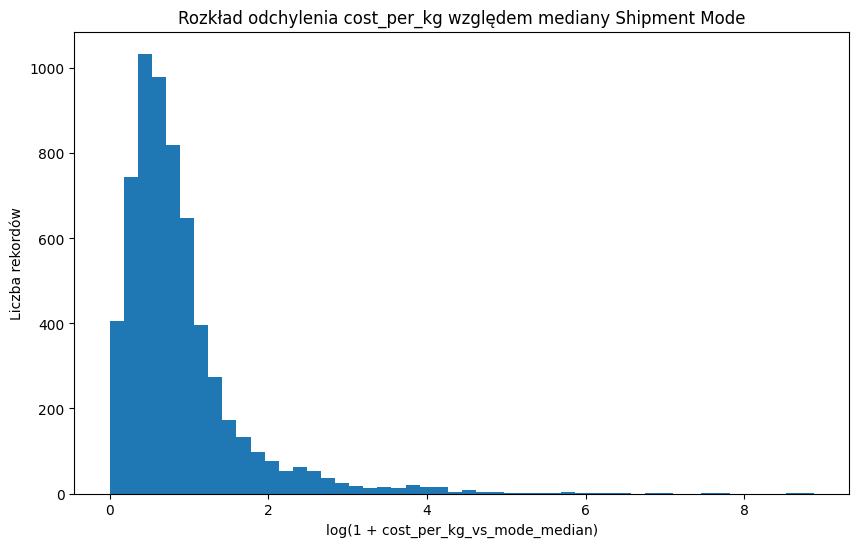

In [78]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))
plt.hist(np.log1p(df_cost["cost_per_kg_vs_mode_median"]), bins=50)
plt.xlabel("log(1 + cost_per_kg_vs_mode_median)")
plt.ylabel("Liczba rekordów")
plt.title("Rozkład odchylenia cost_per_kg względem mediany Shipment Mode")
plt.show()

In [79]:
thresholds = (
    df_cost
    .groupby("Shipment Mode")[[
        "freight_vs_mode_median",
        "cost_per_kg_vs_mode_median",
        "cost_per_unit_vs_mode_median"
    ]]
    .quantile(0.99)
)

thresholds

,freight_vs_mode_median,cost_per_kg_vs_mode_median,cost_per_unit_vs_mode_median
Shipment Mode,,,
Air,16.276471,44.284161,116.209455
Air Charter,7.479660,157.961758,129.079891
Ocean,7.314285,269.222463,241.061962
Truck,11.866250,42.825443,44.526136
Unknown,12.887990,26.565525,230.648766


In [81]:
percentile_cols = [
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median"
]

for col in percentile_cols:
    df_cost[f"{col}_p99"] = (
        df_cost.groupby("Shipment Mode")[col].transform(lambda x: x.quantile(0.99))
    )

In [82]:
df_cost["anomaly_freight_p99"] = (
    df_cost["freight_vs_mode_median"] > df_cost["freight_vs_mode_median_p99"]
)

df_cost["anomaly_cost_per_kg_p99"] = (
    df_cost["cost_per_kg_vs_mode_median"] > df_cost["cost_per_kg_vs_mode_median_p99"]
)

df_cost["anomaly_cost_per_unit_p99"] = (
    df_cost["cost_per_unit_vs_mode_median"] > df_cost["cost_per_unit_vs_mode_median_p99"]
)

df_cost["anomaly_percentile_99"] = (
    df_cost["anomaly_freight_p99"] |
    df_cost["anomaly_cost_per_kg_p99"] |
    df_cost["anomaly_cost_per_unit_p99"]
)

df_cost[[
    "anomaly_freight_p99",
    "anomaly_cost_per_kg_p99",
    "anomaly_cost_per_unit_p99",
    "anomaly_percentile_99"
]].sum()

anomaly_freight_p99           64
anomaly_cost_per_kg_p99       64
anomaly_cost_per_unit_p99     64
anomaly_percentile_99        161
dtype: int64

#FLAGOWANIE POTENCJALNYCH PODEJRZANYCH TRANSPORTÓW

In [83]:
df_cost["anomaly_freight_vs_mode"] = df_cost["freight_vs_mode_median"] > 10

df_cost["anomaly_cost_per_kg_vs_mode"] = df_cost["cost_per_kg_vs_mode_median"] > 10

df_cost["anomaly_cost_per_unit_vs_mode"] = df_cost["cost_per_unit_vs_mode_median"] > 10

df_cost["anomaly_segment_simple"] = (
    df_cost["anomaly_freight_vs_mode"] |
    df_cost["anomaly_cost_per_kg_vs_mode"] |
    df_cost["anomaly_cost_per_unit_vs_mode"]
)

# proba sztywnego ustalenia progu - błedna, trzeba bazować na danych

In [84]:
df_cost["anomaly_freight_p99"] = (
    df_cost["freight_vs_mode_median"] > df_cost["freight_vs_mode_median_p99"]
)

df_cost["anomaly_cost_per_kg_p99"] = (
    df_cost["cost_per_kg_vs_mode_median"] > df_cost["cost_per_kg_vs_mode_median_p99"]
)

df_cost["anomaly_cost_per_unit_p99"] = (
    df_cost["cost_per_unit_vs_mode_median"] > df_cost["cost_per_unit_vs_mode_median_p99"]
)

df_cost["anomaly_percentile_99"] = (
    df_cost["anomaly_freight_p99"] |
    df_cost["anomaly_cost_per_kg_p99"] |
    df_cost["anomaly_cost_per_unit_p99"]
)

df_cost[[
    "anomaly_freight_p99",
    "anomaly_cost_per_kg_p99",
    "anomaly_cost_per_unit_p99",
    "anomaly_percentile_99"
]].sum()

anomaly_freight_p99           64
anomaly_cost_per_kg_p99       64
anomaly_cost_per_unit_p99     64
anomaly_percentile_99        161
dtype: int64

In [85]:
df_cost[[
    "anomaly_freight_vs_mode",
    "anomaly_cost_per_kg_vs_mode",
    "anomaly_cost_per_unit_vs_mode",
    "anomaly_segment_simple"
]].sum()

anomaly_freight_vs_mode          142
anomaly_cost_per_kg_vs_mode      295
anomaly_cost_per_unit_vs_mode    433
anomaly_segment_simple           662
dtype: int64

In [86]:
contamination_value = (
    df_cost["anomaly_percentile_99"].sum()
    / len(df_cost)
)

contamination_value

0.026127880558260305

# sprawdzenie anomalii

In [87]:
df_cost.groupby("Shipment Mode")["anomaly_percentile_99"].agg(["count", "sum", "mean"])

,count,sum,mean
Shipment Mode,,,
Air,4085,109,0.026683
Air Charter,423,10,0.023641
Ocean,282,6,0.021277
Truck,1161,29,0.024978
Unknown,211,7,0.033175


In [88]:
anomaly_by_mode = df_cost.groupby("Shipment Mode")["anomaly_percentile_99"].agg(
    total_records="count",
    anomaly_count="sum",
    anomaly_rate="mean"
)

anomaly_by_mode["anomaly_rate_percent"] = (
    anomaly_by_mode["anomaly_rate"] * 100
).round(2)

anomaly_by_mode

,total_records,anomaly_count,anomaly_rate,anomaly_rate_percent
Shipment Mode,,,,
Air,4085,109,0.026683,2.67
Air Charter,423,10,0.023641,2.36
Ocean,282,6,0.021277,2.13
Truck,1161,29,0.024978,2.50
Unknown,211,7,0.033175,3.32


# wszystko gotowe - przejście do ML

In [49]:
ml_features = [
    "freight_cost_usd_num",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio",
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median"
]

X = df_cost[ml_features].copy()

X.isna().sum()

freight_cost_usd_num            0
weight_kg_num                   0
shipment_total_quantity         0
shipment_total_value            0
cost_per_kg                     0
cost_per_unit                   0
freight_to_value_ratio          0
freight_vs_mode_median          0
cost_per_kg_vs_mode_median      0
cost_per_unit_vs_mode_median    0
dtype: int64

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled.shape

(6162, 10)

dane przygotowane, przejscie do IsolationForest - 300 drzew, 0,0261 spodziewanych odchylen, stała 42

In [ ]:
from sklearn.ensemble import IsolationForest

iforest = IsolationForest(
    n_estimators=300,
    contamination=0.0261,
    random_state=42
)

df_cost["iforest_pred"] = iforest.fit_predict(X_scaled)
df_cost["anomaly_iforest"] = df_cost["iforest_pred"] == -1
df_cost["iforest_score"] = iforest.decision_function(X_scaled)

df_cost["anomaly_iforest"].sum()

309

In [90]:
comparison_iforest = pd.crosstab(
    df_cost["anomaly_percentile_99"],
    df_cost["anomaly_iforest"],
    rownames=["Percentile 99"],
    colnames=["Isolation Forest"]
)

comparison_iforest

Isolation Forest,False,True
Percentile 99,,
False,5948,53
True,53,108


In [91]:
def compare_methods(row):
    if row["anomaly_percentile_99"] and row["anomaly_iforest"]:
        return "Both"
    elif row["anomaly_percentile_99"] and not row["anomaly_iforest"]:
        return "Only Percentile"
    elif not row["anomaly_percentile_99"] and row["anomaly_iforest"]:
        return "Only Isolation Forest"
    else:
        return "Normal"

df_cost["anomaly_comparison_group"] = df_cost.apply(compare_methods, axis=1)

df_cost["anomaly_comparison_group"].value_counts()

Normal                   5948
Both                      108
Only Percentile            53
Only Isolation Forest      53
Name: anomaly_comparison_group, dtype: int64

In [92]:
df_cost.groupby("anomaly_comparison_group")[[
    "freight_cost_usd_num",
    "weight_kg_num",
    "shipment_total_quantity",
    "shipment_total_value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio",
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median"
]].median()

,freight_cost_usd_num,weight_kg_num,shipment_total_quantity,shipment_total_value,cost_per_kg,cost_per_unit,freight_to_value_ratio,freight_vs_mode_median,cost_per_kg_vs_mode_median,cost_per_unit_vs_mode_median
anomaly_comparison_group,,,,,,,,,,
Both,12639.795,44.0,99.0,997.98,170.147051,46.174447,3.240315,2.269763,16.991376,56.724492
Normal,5737.075,1051.0,6201.5,78964.00,7.130845,0.842846,0.085494,0.985069,0.989828,0.983465
Only Isolation Forest,40616.150,38799.0,325425.0,2801088.00,1.108618,0.126568,0.017650,4.945528,0.395692,0.472063
Only Percentile,8495.830,118.0,2159.0,50520.60,34.934783,6.630417,0.353327,1.432856,7.504923,6.076667


# kolejny model - LocalOutlierFactor i porownanie wynikow, w szczegolnosci czy oznaczone rekordy sie powtarzaja

In [93]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.0261
)

df_cost["lof_pred"] = lof.fit_predict(X_scaled)
df_cost["anomaly_lof"] = df_cost["lof_pred"] == -1
df_cost["lof_score"] = lof.negative_outlier_factor_

df_cost["anomaly_lof"].sum()

161

In [94]:
comparison_all = pd.DataFrame({
    "percentile_99": df_cost["anomaly_percentile_99"],
    "isolation_forest": df_cost["anomaly_iforest"],
    "lof": df_cost["anomaly_lof"]
})

comparison_all.sum()

percentile_99       161
isolation_forest    161
lof                 161
dtype: int64

In [95]:
df_cost["anomaly_votes"] = (
    df_cost["anomaly_percentile_99"].astype(int)
    + df_cost["anomaly_iforest"].astype(int)
    + df_cost["anomaly_lof"].astype(int)
)

df_cost["anomaly_votes"].value_counts().sort_index()

0    5842
1     199
2      79
3      42
Name: anomaly_votes, dtype: int64

In [58]:
df_cost["final_anomaly"] = df_cost["anomaly_votes"] >= 2

df_cost["final_anomaly"].sum()

121

# 121
 anomalii oznaczonych przez wszystkie przynajmniej 2 metody - percentyle, ISO i LOF

finalne anomalie - co to za rekordy

In [59]:
df_cost[df_cost["final_anomaly"]].sort_values(
    ["anomaly_votes", "cost_per_kg_vs_mode_median", "cost_per_unit_vs_mode_median"],
    ascending=[False, False, False]
)[[
    "Shipment Mode",
    "freight_cost_usd_num",
    "weight_kg_num",
    "Line Item Quantity",
    "Line Item Value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio",
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median",
    "anomaly_votes",
    "anomaly_percentile_99",
    "anomaly_iforest",
    "anomaly_lof"
]].head(20)

,Shipment Mode,freight_cost_usd_num,weight_kg_num,Line Item Quantity,Line Item Value,cost_per_kg,cost_per_unit,freight_to_value_ratio,freight_vs_mode_median,cost_per_kg_vs_mode_median,cost_per_unit_vs_mode_median,anomaly_votes,anomaly_percentile_99,anomaly_iforest,anomaly_lof
6005,Air Charter,124350.82,4.0,64,156.16,31087.705000,1942.981563,796.303919,8.115448,7199.919311,4434.606511,3,True,True,True
5515,Air Charter,45180.62,2.0,10534,97966.20,22590.310000,4.289028,0.461186,2.948601,5231.920761,9.789157,3,True,True,True
543,Unknown,9789.07,1.0,2,160.00,9789.070000,4894.535000,61.181687,3.351274,2102.953430,8631.204993,3,True,True,True
6102,Truck,5220.79,1.0,25,169.00,5220.790000,208.831600,30.892249,0.869842,2087.119195,831.886536,3,True,True,True
852,Air,19480.97,1.0,5,58.75,19480.970000,3896.194000,331.590979,4.071947,1945.425951,2219.471154,3,True,True,True
2938,Ocean,19518.98,10.0,120,541.20,1951.898000,162.658167,36.066112,2.050103,1161.139212,1046.076156,3,True,True,True
3447,Ocean,9951.38,6.0,70,315.70,1658.563333,142.162571,31.521634,1.045206,986.641167,914.266276,3,True,True,True
148,Air,12561.40,2.0,5,160.00,6280.700000,2512.280000,78.508750,2.625606,627.208849,1431.123037,3,True,True,True
4525,Truck,10891.66,8.0,4226,34906.76,1361.457500,0.388350,0.040347,1.814672,544.270902,1.547003,3,True,True,True
3659,Ocean,8809.05,11.0,100,665.00,800.822727,88.090500,13.246692,0.925226,476.391015,566.521642,3,True,True,True


In [60]:
final_by_mode = df_cost.groupby("Shipment Mode")["final_anomaly"].agg(
    total_records="count",
    final_anomaly_count="sum",
    final_anomaly_rate="mean"
)

final_by_mode["final_anomaly_rate_percent"] = (
    final_by_mode["final_anomaly_rate"] * 100
).round(2)

final_by_mode

,total_records,final_anomaly_count,final_anomaly_rate,final_anomaly_rate_percent
Shipment Mode,,,,
Air,4085,79,0.019339,1.93
Air Charter,423,10,0.023641,2.36
Ocean,282,5,0.017730,1.77
Truck,1161,23,0.019811,1.98
Unknown,211,4,0.018957,1.90


oznaczenie powodu anomalii

In [61]:
def anomaly_type(row):
    types = []

    if row["anomaly_freight_p99"]:
        types.append("High total freight")

    if row["anomaly_cost_per_kg_p99"]:
        types.append("High cost per kg")

    if row["anomaly_cost_per_unit_p99"]:
        types.append("High cost per unit")

    if len(types) == 0:
        return "ML multivariate anomaly"

    return " + ".join(types)

df_cost["anomaly_type"] = df_cost.apply(anomaly_type, axis=1)

df_cost["anomaly_type"].value_counts()

ML multivariate anomaly                                       6001
High total freight                                              63
High cost per kg                                                34
High cost per unit                                              34
High cost per kg + High cost per unit                           29
High total freight + High cost per kg + High cost per unit       1
Name: anomaly_type, dtype: int64

In [62]:
df_cost["anomaly_rank_score"] = (
    df_cost["anomaly_votes"] * 1000
    + df_cost["cost_per_kg_vs_mode_median"]
    + df_cost["cost_per_unit_vs_mode_median"]
    + df_cost["freight_vs_mode_median"]
)

df_cost[df_cost["final_anomaly"]].sort_values(
    "anomaly_rank_score",
    ascending=False
)[[
    "Shipment Mode",
    "freight_cost_usd_num",
    "weight_kg_num",
    "Line Item Quantity",
    "Line Item Value",
    "cost_per_kg",
    "cost_per_unit",
    "freight_to_value_ratio",
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median",
    "anomaly_votes",
    "anomaly_type",
    "anomaly_rank_score"
]].head(20)

,Shipment Mode,freight_cost_usd_num,weight_kg_num,Line Item Quantity,Line Item Value,cost_per_kg,cost_per_unit,freight_to_value_ratio,freight_vs_mode_median,cost_per_kg_vs_mode_median,cost_per_unit_vs_mode_median,anomaly_votes,anomaly_type,anomaly_rank_score
6005,Air Charter,124350.82,4.0,64,156.16,31087.705000,1942.981563,796.303919,8.115448,7199.919311,4434.606511,3,High total freight + High cost per kg + High c...,14642.641270
543,Unknown,9789.07,1.0,2,160.00,9789.070000,4894.535000,61.181687,3.351274,2102.953430,8631.204993,3,High cost per kg + High cost per unit,13737.509697
3020,Air,14515.01,1370.0,1,89.00,10.594898,14515.010000,163.090000,3.033954,1.058037,8268.491249,3,High cost per unit,11272.583240
3081,Air,13753.58,1233.0,1,89.00,11.154566,13753.580000,154.534607,2.874798,1.113927,7834.741821,3,High cost per unit,10838.730546
1832,Air,11034.01,985.0,1,89.00,11.202041,11034.010000,123.977640,2.306349,1.118668,6285.535809,3,High cost per unit,9288.960826
1559,Air,10083.69,1028.0,1,80.00,9.809037,10083.690000,126.046125,2.107711,0.979559,5744.184987,3,High cost per unit,8747.272256
5515,Air Charter,45180.62,2.0,10534,97966.20,22590.310000,4.289028,0.461186,2.948601,5231.920761,9.789157,3,High cost per kg,8244.658519
2010,Air,8826.00,800.0,1,89.00,11.032500,8826.000000,99.168539,1.844826,1.101737,5027.740509,3,High cost per unit,8030.687073
2885,Air,8664.89,822.0,1,80.00,10.541229,8664.890000,108.311125,1.811151,1.052678,4935.964022,3,High cost per unit,7938.827850
852,Air,19480.97,1.0,5,58.75,19480.970000,3896.194000,331.590979,4.071947,1945.425951,2219.471154,3,High cost per kg + High cost per unit,7168.969052


In [63]:
def anomaly_combination(row):
    methods = []

    if row["anomaly_percentile_99"]:
        methods.append("Percentyl")
    if row["anomaly_iforest"]:
        methods.append("Isolation Forest")
    if row["anomaly_lof"]:
        methods.append("LOF")

    if len(methods) == 0:
        return "Brak anomalii"

    return " + ".join(methods)

df_cost["anomaly_combination"] = df_cost.apply(
    anomaly_combination,
    axis=1
)

combination_counts = (
    df_cost["anomaly_combination"]
    .value_counts()
    .rename_axis("Kombinacja metod")
    .reset_index(name="Liczba rekordów")
)

combination_counts

,Kombinacja metod,Liczba rekordów
0,Brak anomalii,5842
1,LOF,106
2,Percentyl + Isolation Forest,66
3,Isolation Forest,49
4,Percentyl,44
5,Percentyl + Isolation Forest + LOF,42
6,Percentyl + LOF,9
7,Isolation Forest + LOF,4


In [64]:

all_three_ids = [
    86277,
    84931,
    54965,
    81579
]


percentile_only = df_cost[
    (df_cost["anomaly_percentile_99"]) &
    (~df_cost["anomaly_iforest"]) &
    (~df_cost["anomaly_lof"])
].copy()


percentile_only["max_relative_indicator"] = percentile_only[[
    "freight_vs_mode_median",
    "cost_per_kg_vs_mode_median",
    "cost_per_unit_vs_mode_median"
]].max(axis=1)

percentile_only_id = (
    percentile_only
    .sort_values("max_relative_indicator", ascending=False)
    .iloc[0]["ID"]
)


if_only_id = 85506
lof_only_id = 47301

selected_ids = (
    all_three_ids
    + [percentile_only_id, if_only_id, lof_only_id]
)

selected = df_cost[
    df_cost["ID"].isin(selected_ids)
].copy()

selected[[
    "ID",
    "ASN/DN #",
    "Shipment Mode",
    "anomaly_percentile_99",
    "anomaly_iforest",
    "anomaly_lof",
    "anomaly_votes"
]]

,ID,ASN/DN #,Shipment Mode,anomaly_percentile_99,anomaly_iforest,anomaly_lof,anomaly_votes
1751,17701,ASN-15931,Air,True,False,False,1
2836,47301,ASN-29746,Air,False,False,True,1
3081,54965,ASN-8590,Air,True,True,True,3
3999,81579,ASN-15670,Air,True,True,True,3
5515,84931,DN-3720,Air Charter,True,True,True,3
5737,85506,DN-3819,Truck,False,True,False,1
6005,86277,DN-1683,Air Charter,True,True,True,3


In [100]:
selected_ids = [
    1179,   # Percentyl + Isolation Forest
    17701,  # tylko Percentyl
    47301,  # tylko LOF
    54965,  # wszystkie 3 metody
    81579,  # wszystkie 3 metody
    84931,  # wszystkie 3 metody
    85506,  # tylko Isolation Forest
    86277   # wszystkie 3 metody
]

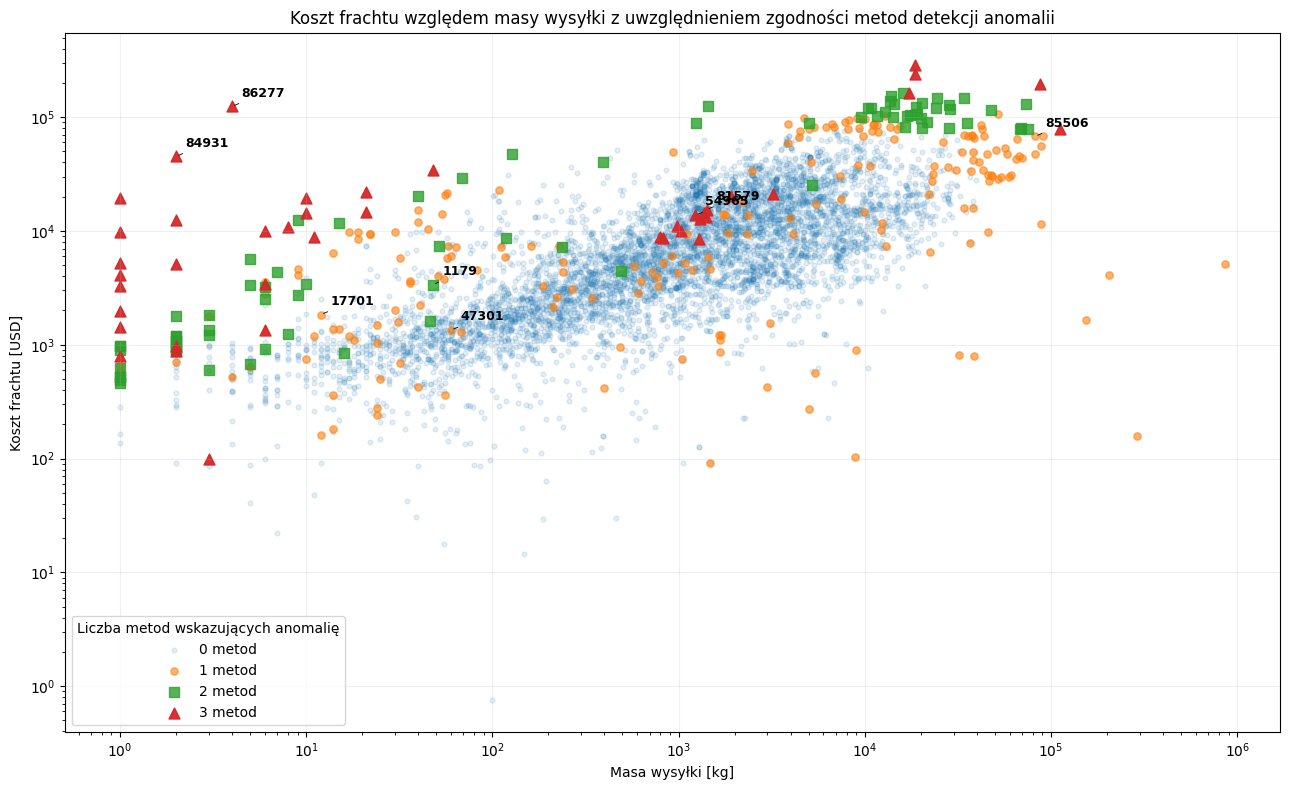

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 8))

markers = {
    0: "o",
    1: "o",
    2: "s",
    3: "^"
}

sizes = {
    0: 12,
    1: 28,
    2: 42,
    3: 62
}

alphas = {
    0: 0.12,
    1: 0.60,
    2: 0.80,
    3: 0.95
}

for votes in [0, 1, 2, 3]:

    subset = df_cost[
        df_cost["anomaly_votes"] == votes
    ]

    plt.scatter(
        subset["weight_kg_num"],
        subset["freight_cost_usd_num"],
        s=sizes[votes],
        alpha=alphas[votes],
        marker=markers[votes],
        label=f"{votes} metod"
    )


selected = df_cost[
    df_cost["ID"].isin(selected_ids)
]

for _, row in selected.iterrows():

    plt.annotate(
        str(int(row["ID"])),
        (
            row["weight_kg_num"],
            row["freight_cost_usd_num"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-",
            linewidth=0.6
        )
    )


plt.xscale("log")
plt.yscale("log")

plt.xlabel("Masa wysyłki [kg]")
plt.ylabel("Koszt frachtu [USD]")

plt.title(
    "Koszt frachtu względem masy wysyłki "
    "z uwzględnieniem zgodności metod detekcji anomalii"
)

plt.legend(
    title="Liczba metod wskazujących anomalię",
    loc="lower left"
)

plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "wykres_anomalie_5_6.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [96]:
from sklearn.metrics import jaccard_score

jaccard_percentile_iforest = jaccard_score(
    df_cost["anomaly_percentile_99"],
    df_cost["anomaly_iforest"]
)

jaccard_percentile_lof = jaccard_score(
    df_cost["anomaly_percentile_99"],
    df_cost["anomaly_lof"]
)

jaccard_iforest_lof = jaccard_score(
    df_cost["anomaly_iforest"],
    df_cost["anomaly_lof"]
)

print("Percentyl vs Isolation Forest:", jaccard_percentile_iforest)
print("Percentyl vs LOF:", jaccard_percentile_lof)
print("Isolation Forest vs LOF:", jaccard_iforest_lof)

Percentyl vs Isolation Forest: 0.5046728971962616
Percentyl vs LOF: 0.1881918819188192
Isolation Forest vs LOF: 0.16666666666666666


In [97]:
jaccard_results = pd.DataFrame({
    "Porównanie": [
        "Percentyl vs Isolation Forest",
        "Percentyl vs LOF",
        "Isolation Forest vs LOF"
    ],
    "Jaccard": [
        jaccard_percentile_iforest,
        jaccard_percentile_lof,
        jaccard_iforest_lof
    ]
})

jaccard_results

,Porównanie,Jaccard
0,Percentyl vs Isolation Forest,0.504673
1,Percentyl vs LOF,0.188192
2,Isolation Forest vs LOF,0.166667


In [ ]:
ids_to_check = [
    86277,
    84931,
    54965,
    81579,
    1179,
    85506,
    47301,
    17701
]

def get_methods(row):
    methods = []

    if row["anomaly_percentile_99"]:
        methods.append("Percentyl")
    if row["anomaly_iforest"]:
        methods.append("Isolation Forest")
    if row["anomaly_lof"]:
        methods.append("LOF")

    if len(methods) == 0:
        return "Brak"

    return " + ".join(methods)


selected_anomalies = df_cost[
    df_cost["ID"].isin(ids_to_check)
].copy()

selected_anomalies["Metody"] = selected_anomalies.apply(
    get_methods,
    axis=1
)

table_5_6 = selected_anomalies[
    [
        "ID",
        "Shipment Mode",
        "freight_cost_usd_num",
        "weight_kg_num",
        "shipment_total_quantity",
        "shipment_total_value",
        "cost_per_kg_vs_mode_median",
        "cost_per_unit_vs_mode_median",
        "anomaly_percentile_99",
        "anomaly_iforest",
        "anomaly_lof",
        "Metody"
    ]
].copy()

table_5_6 = table_5_6.rename(columns={
    "Shipment Mode": "Tryb transportu",
    "freight_cost_usd_num": "Koszt frachtu [USD]",
    "weight_kg_num": "Masa [kg]",
    "shipment_total_quantity": "Liczba jednostek",
    "shipment_total_value": "Wartość towaru [USD]",
    "cost_per_kg_vs_mode_median": "Cost/kg vs mediana",
    "cost_per_unit_vs_mode_median": "Cost/unit vs mediana",
    "anomaly_percentile_99": "Percentyl",
    "anomaly_iforest": "Isolation Forest",
    "anomaly_lof": "LOF"
})

table_5_6.sort_values("ID")

,ID,Tryb transportu,Koszt frachtu [USD],Masa [kg],Liczba jednostek,Wartość towaru [USD],Cost/kg vs mediana,Cost/unit vs mediana,Percentyl,Isolation Forest,LOF,Metody
69,1179,Air,3366.04,48.0,8,613.76,7.002968,239.683544,True,True,False,Percentyl + Isolation Forest
1751,17701,Air,1840.97,12.0,5,2000.00,15.320382,209.742113,True,False,False,Percentyl
2836,47301,Air,1344.94,60.0,814,0.01,2.238493,0.941212,False,False,True,LOF
3081,54965,Air,13753.58,1233.0,1,89.00,1.113927,7834.741821,True,True,True,Percentyl + Isolation Forest + LOF
3999,81579,Air,15387.63,1413.0,4,356.00,1.087511,2191.395046,True,True,True,Percentyl + Isolation Forest + LOF
5515,84931,Air Charter,45180.62,2.0,10534,97966.20,5231.920761,9.789157,True,True,True,Percentyl + Isolation Forest + LOF
5737,85506,Truck,67855.39,82137.0,633780,6832148.40,0.330260,0.426495,False,True,False,Isolation Forest
6005,86277,Air Charter,124350.82,4.0,64,156.16,7199.919311,4434.606511,True,True,True,Percentyl + Isolation Forest + LOF


IF liczba drzew stabilność

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import jaccard_score
import pandas as pd

n_estimators_values = [100, 200, 300, 500]

if_results = {}

for n in n_estimators_values:
    model = IsolationForest(
        n_estimators=n,
        contamination=0.0261,
        random_state=42
    )

    pred = model.fit_predict(X_scaled)

    if_results[n] = pred == -1


if_stability = []

baseline = if_results[300]

for n in n_estimators_values:
    if_stability.append({
        "n_estimators": n,
        "liczba_anomalii": if_results[n].sum(),
        "Jaccard_vs_300": jaccard_score(
            baseline,
            if_results[n]
        )
    })

if_stability = pd.DataFrame(if_stability)

if_stability

,n_estimators,liczba_anomalii,Jaccard_vs_300
0,100,161,0.872093
1,200,161,0.963415
2,300,161,1.000000
3,500,161,0.963415


Liczba sasiadow LOF stablinosc

In [ ]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import jaccard_score
import pandas as pd

n_neighbors_values = [10, 20, 30, 50]

lof_results = {}

for n in n_neighbors_values:
    model = LocalOutlierFactor(
        n_neighbors=n,
        contamination=0.0261
    )

    pred = model.fit_predict(X_scaled)

    lof_results[n] = pred == -1


lof_stability = []

baseline = lof_results[20]

for n in n_neighbors_values:
    lof_stability.append({
        "n_neighbors": n,
        "liczba_anomalii": lof_results[n].sum(),
        "Jaccard_vs_20": jaccard_score(
            baseline,
            lof_results[n]
        )
    })

lof_stability = pd.DataFrame(lof_stability)

lof_stability

,n_neighbors,liczba_anomalii,Jaccard_vs_20
0,10,161,0.594059
1,20,161,1.000000
2,30,161,0.750000
3,50,161,0.477064


Stabilność LOF contamination

In [108]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import jaccard_score
import pandas as pd

contamination_values = [0.01, 0.02, 0.0261, 0.03, 0.05]

if_contamination_results = {}
lof_contamination_results = {}

for c in contamination_values:

    # Isolation Forest
    if_model = IsolationForest(
        n_estimators=300,
        contamination=c,
        random_state=42
    )

    if_pred = if_model.fit_predict(X_scaled)
    if_contamination_results[c] = if_pred == -1


    # LOF
    lof_model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=c
    )

    lof_pred = lof_model.fit_predict(X_scaled)
    lof_contamination_results[c] = lof_pred == -1

In [109]:
baseline_contamination = 0.0261

if_baseline = if_contamination_results[baseline_contamination]
lof_baseline = lof_contamination_results[baseline_contamination]

contamination_stability = []

for c in contamination_values:

    contamination_stability.append({
        "contamination": c,

        "IF_liczba_anomalii":
            if_contamination_results[c].sum(),

        "IF_Jaccard_vs_0.0261":
            jaccard_score(
                if_baseline,
                if_contamination_results[c]
            ),

        "LOF_liczba_anomalii":
            lof_contamination_results[c].sum(),

        "LOF_Jaccard_vs_0.0261":
            jaccard_score(
                lof_baseline,
                lof_contamination_results[c]
            )
    })

contamination_stability = pd.DataFrame(
    contamination_stability
)

contamination_stability

,contamination,IF_liczba_anomalii,IF_Jaccard_vs_0.0261,LOF_liczba_anomalii,LOF_Jaccard_vs_0.0261
0,0.0100,62,0.385093,62,0.385093
1,0.0200,124,0.770186,124,0.770186
2,0.0261,161,1.000000,161,1.000000
3,0.0300,185,0.870270,185,0.870270
4,0.0500,309,0.521036,309,0.521036
